# 📓 Pre-Workshop Notebook 4: Cleaning and Processing Research Signals
## Scientific Workflows for Brain and Behavioral Research
### National Science Foundation Supported Learning Initiative (Award No. OAC-2417875)

---

## 📋 Set Up Your Profile
*Run the cell below to record your progress.*

In [1]:
# PROFILE SYNC
student_name = "Jade"
institution = "Mizzou"
active_notebook = "Notebook 04 — Signal Cleaning and Processing"

print(f"✅ Profile synced for {student_name} ({institution})")
print(f"Current notebook: {active_notebook}")

✅ Profile synced for Jade (Mizzou)
Current notebook: Notebook 04 — Signal Cleaning and Processing


---

## 🤖 Using AI Tools to Build Your Workflow ("Ask → Build → Document")

As a **Workflow Designer** working with signal data, your main responsibility is making sure the signal you are analyzing is clean and meaningful. AI tools are good at applying mathematical filters, but they sometimes miss edge cases — such as what to do when a recording contains a sudden spike from a movement artifact, or when a calculation produces an unexpected result.

When using the **Ask → Build → Document** cycle in this notebook, ask the AI to explain what its filtering steps do in plain language, and to flag any parts of the data that could not be processed cleanly.

---
## 🧠 Part A: Cleaning Raw Recordings
### Topic: Removing Noise, Filtering Signals, and Visualizing Frequency Content

This section introduces the core signal processing steps that transform raw, noisy recordings into clean data ready for analysis.

### 🧭 Activity A.1 — Filtering a Noisy Brain Signal

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a signal processing instructor explaining brain signal cleaning to a biology student. Write a Python script using SciPy and Matplotlib that demonstrates how to clean a noisy brain recording. The script should:
> 1. Generate 5 seconds of a simulated brain signal recorded at 500 measurements per second, combining a realistic 10 Hz brain rhythm, electrical interference at 60 Hz from the building's power supply, and a sudden large spike representing a participant's eye blink or muscle movement.
> 2. Explain in a comment how the Nyquist rule determines what sampling rate is needed to accurately capture this signal.
> 3. Apply a digital bandpass filter to isolate the 10 Hz brain rhythm while removing the 60 Hz electrical noise.
> 4. Add a simple threshold detector that flags and removes the eye blink spike from the recording.
> 5. Display plots of the raw signal, the filtered signal, and the cleaned signal side-by-side.
> Use plain-language comments throughout explaining what each step does biologically and mathematically."

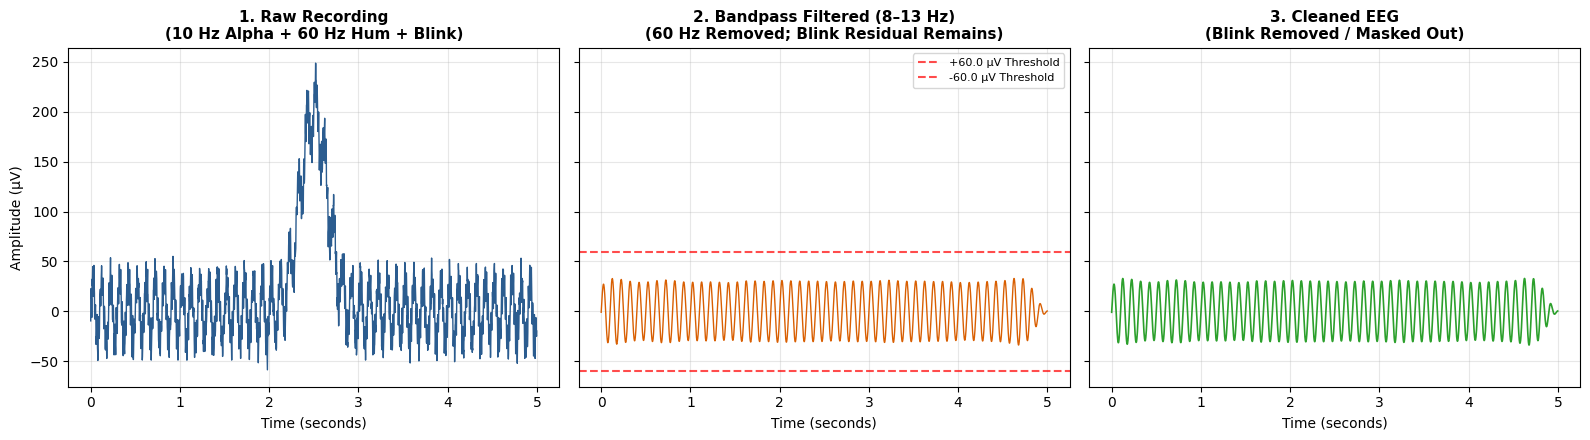

In [2]:
# 💻 Activity A.1 — Paste your AI-generated Signal Filtering code here:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# ==============================================================================
# 1. SIMULATE BRAIN RECORDING (EEG)
# ==============================================================================

# Sampling parameters
sampling_rate = 500  # 500 samples per second (Hz)
duration = 5.0       # 5 seconds
time = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)

# --- NYQUIST THEOREM EXPLANATION ---
# The Nyquist-Shannon Sampling Theorem states that to accurately record an analog
# signal without distortion ("aliasing"), your sampling rate must be at least
# TWICE the highest frequency present in the recording (f_s >= 2 * f_max).
#
# Here, the highest prominent frequency is the 60 Hz electrical interference.
# Therefore, the theoretical minimum sampling rate required is:
#     2 * 60 Hz = 120 Hz
#
# Our chosen rate of 500 Hz comfortably exceeds this limit (Nyquist frequency = 250 Hz),
# ensuring all dynamics below 250 Hz are captured faithfully.

# Component A: Alpha wave (~10 Hz)
# Biologically, synchronous neural firing in cortical pyramidal neurons (e.g., occipital lobe)
# produces rhythmic field potentials around 8-12 Hz (~20-50 µV in amplitude).
alpha_wave = 30.0 * np.sin(2 * np.pi * 10.0 * time)

# Component B: Background cortical broadband noise
# Ongoing, non-synchronized micro-activity in the cortex modeled as low-amplitude white noise.
cortical_noise = np.random.normal(0, 5.0, size=len(time))

# Component C: Power line hum (60 Hz interference)
# Electromagnetic radiation from AC wall outlets and lab lighting couples into the electrode leads.
powerline_hum = 15.0 * np.sin(2 * np.pi * 60.0 * time)

# Component D: Eye-blink artifact (transient large deflection)
# The human eye is an electrical dipole (cornea is positive relative to the retina).
# Blinking slides the eyelid over the cornea, producing a massive low-frequency spike (~200+ µV).
artifact = np.zeros_like(time)
blink_center = 2.5  # blink occurs at 2.5 seconds
blink_width = 0.15  # duration of ~300 ms
artifact += 200.0 * np.exp(-0.5 * ((time - blink_center) / blink_width) ** 2)

# Raw recorded EEG signal (superposition of all sources)
raw_signal = alpha_wave + cortical_noise + powerline_hum + artifact


# ==============================================================================
# 2. BANDPASS FILTERING (ISOLATE 10 Hz, ELIMINATE 60 Hz)
# ==============================================================================

# We define a bandpass filter targeting the alpha band: 8 Hz to 13 Hz.
# This passes the biological 10 Hz rhythm while stripping out high-frequency powerline
# noise (60 Hz) as well as DC/slow drift.
lowcut = 8.0
highcut = 13.0

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    """
    Constructs and applies a Butterworth bandpass filter.
    Uses filtfilt (zero-phase filtering) by passing forward and backward,
    preventing phase distortion so peak timings remain biologically true.
    """
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

filtered_signal = butter_bandpass_filter(raw_signal, lowcut, highcut, sampling_rate)


# ==============================================================================
# 3. THRESHOLD ARTIFACT REJECTION
# ==============================================================================

# Bandpass filtering reduces high-frequency noise, but high-amplitude spikes (like blinks)
# still leak energy into the passband and distort the true biological amplitude.
#
# Biologically, resting scalp EEG rarely exceeds +/- 75-100 µV. Any voltage exceeding
# this physiological threshold is flagged as an artifact.
voltage_threshold = 60.0  # µV in the filtered stream

artifact_indices = np.abs(filtered_signal) > voltage_threshold

# Create a cleaned version where artifact segments are blanked out (set to NaN)
# so downstream calculations (e.g., spectral power) aren't biased by muscle/blink data.
cleaned_signal = filtered_signal.copy()
cleaned_signal[artifact_indices] = np.nan


# ==============================================================================
# 4. VISUALIZATION
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

# Plot 1: Raw EEG
axes[0].plot(time, raw_signal, color='#2b5c8f', lw=1.0)
axes[0].set_title("1. Raw Recording\n(10 Hz Alpha + 60 Hz Hum + Blink)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude (µV)")
axes[0].grid(True, alpha=0.3)

# Plot 2: Bandpass Filtered EEG
axes[1].plot(time, filtered_signal, color='#d95f02', lw=1.0)
axes[1].axhline(voltage_threshold, color='red', linestyle='--', alpha=0.7, label=f"+{voltage_threshold} µV Threshold")
axes[1].axhline(-voltage_threshold, color='red', linestyle='--', alpha=0.7, label=f"-{voltage_threshold} µV Threshold")
axes[1].set_title("2. Bandpass Filtered (8–13 Hz)\n(60 Hz Removed; Blink Residual Remains)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Time (seconds)")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].grid(True, alpha=0.3)

# Plot 3: Cleaned EEG (Artifacts Masked)
axes[2].plot(time, cleaned_signal, color='#2ca02c', lw=1.2)
axes[2].set_title("3. Cleaned EEG\n(Blink Removed / Masked Out)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Time (seconds)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 🧭 Activity A.2 — Visualizing How Signals Change Over Time

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a neuroscience data visualization instructor. Write a Python script using SciPy and Matplotlib that shows how to create a time-frequency plot (spectrogram) of a brain signal. The script should:
> 1. Generate a signal that shifts from a slow rhythm (8 Hz, representing a resting brain state) for the first 2 seconds, then transitions to a faster rhythm (25 Hz, representing an active brain state) for the final 3 seconds.
> 2. Compute a spectrogram of this signal that shows how its frequency content changes over time.
> 3. Display the spectrogram with a color scale showing signal strength, with time on the horizontal axis and frequency on the vertical axis.
> Add plain-language comments explaining what a spectrogram reveals that a simple time-series plot cannot."

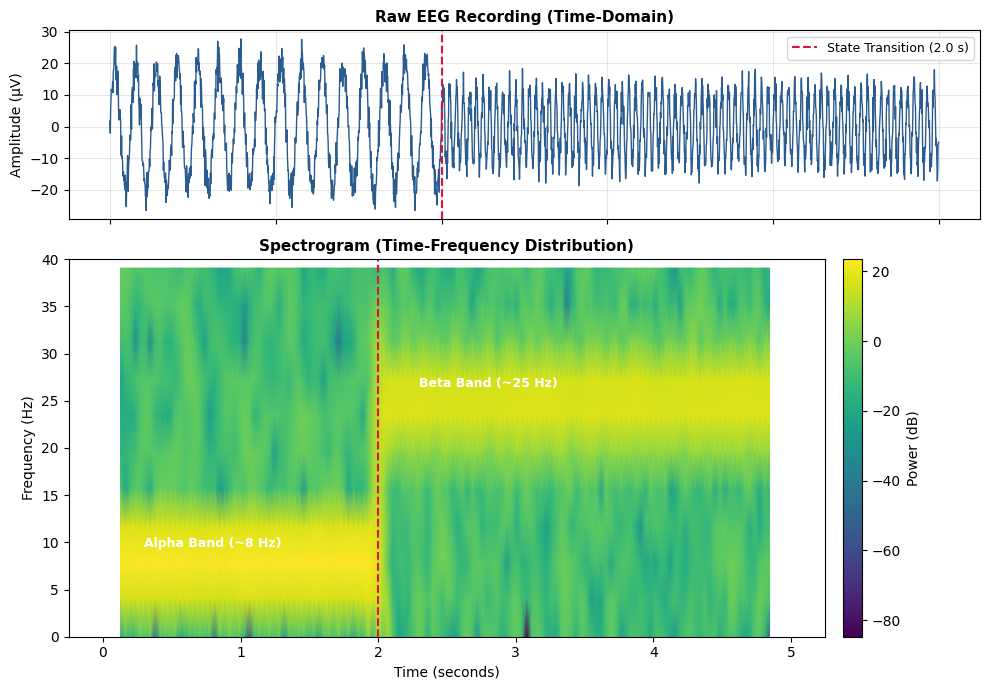

In [3]:
# 💻 Activity A.2 — Paste your AI-generated Spectrogram code here:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# ==============================================================================
# 1. SIMULATE A DYNAMIC BRAIN STATE TRANSITION
# ==============================================================================

# Sampling parameters: 500 Hz comfortably satisfies the Nyquist rule for frequencies < 250 Hz.
fs = 500               # Sampling frequency (samples/sec)
total_duration = 5.0   # Total record length in seconds
time = np.linspace(0, total_duration, int(fs * total_duration), endpoint=False)

# Split time vector: 0 to 2 seconds (Resting), 2 to 5 seconds (Active/Engaged)
mask_rest = time < 2.0
mask_active = time >= 2.0

# Resting State (0–2 s): Dominated by an ~8 Hz alpha rhythm (synchronized cortical idling)
alpha_burst = 20.0 * np.sin(2 * np.pi * 8.0 * time[mask_rest])

# Active State (2–5 s): Desynchronization shifts power to a ~25 Hz beta rhythm (active processing)
beta_burst = 12.0 * np.sin(2 * np.pi * 25.0 * time[mask_active])

# Concatenate into one continuous neurophysiological time series + broadband background noise
signal = np.concatenate([alpha_burst, beta_burst])
signal += np.random.normal(0, 3.0, size=len(signal))  # Unsynchronized cortical background activity


# ==============================================================================
# 2. COMPUTE THE SPECTROGRAM (SHORT-TIME FOURIER TRANSFORM)
# ==============================================================================
#
# --- WHY A SPECTROGRAM INSTEAD OF A STANDARD TIME-SERIES OR FOURIER TRANSFORM? ---
# 1. A raw voltage-over-time plot shows fluctuations, but cannot disentangle which
#    underlying neural oscillations are active when rhythms overlap or change rapidly.
# 2. A standard Fourier Transform (FFT) reveals which frequencies exist across the ENTIRE
#    epoch (showing peaks at both 8 Hz and 25 Hz), but it discards temporal information—
#    you cannot tell *when* each rhythm occurred.
# 3. A Spectrogram uses sliding time windows (STFT) to map spectral power simultaneously
#    across BOTH time and frequency, pinpointing exact state transitions.

# Window parameters:
# - nperseg (window length): Controls the time-frequency trade-off (Gabor limit).
#   128 points (~0.256 s) offers good temporal resolution while keeping ~3.9 Hz frequency bins.
# - noverlap: Overlapping adjacent windows by 85% ensures smooth temporal continuity.
frequencies, times, Sxx = spectrogram(
    signal,
    fs=fs,
    window='hann',
    nperseg=128,
    noverlap=110,
    scaling='spectrum'
)

# Convert power spectral density to decibels (dB) for biological visualization
# (neuronal power naturally drops following a 1/f slope, so a log/dB scale ensures
# lower-power high frequencies remain clearly visible alongside dominant low rhythms).
Sxx_db = 10 * np.log10(Sxx + 1e-12)


# ==============================================================================
# 3. VISUALIZATION: TIME-SERIES VS. SPECTROGRAM
# ==============================================================================

fig, (ax_raw, ax_spec) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2]})

# Top Panel: Raw Voltage Trace (Time Domain)
ax_raw.plot(time, signal, color='#2b5c8f', lw=1.0)
ax_raw.axvline(2.0, color='crimson', linestyle='--', lw=1.5, label='State Transition (2.0 s)')
ax_raw.set_ylabel("Amplitude (µV)", fontsize=10)
ax_raw.set_title("Raw EEG Recording (Time-Domain)", fontsize=11, fontweight='bold')
ax_raw.legend(loc="upper right", fontsize=9)
ax_raw.grid(True, alpha=0.3)

# Bottom Panel: Spectrogram (Time-Frequency Domain)
# Limit frequency display to 0–40 Hz to highlight relevant classical EEG bands (Alpha & Beta)
freq_mask = frequencies <= 40
im = ax_spec.pcolormesh(
    times,
    frequencies[freq_mask],
    Sxx_db[freq_mask, :],
    shading='gouraud',
    cmap='viridis'
)

ax_spec.axvline(2.0, color='crimson', linestyle='--', lw=1.5)
ax_spec.set_title("Spectrogram (Time-Frequency Distribution)", fontsize=11, fontweight='bold')
ax_spec.set_xlabel("Time (seconds)", fontsize=10)
ax_spec.set_ylabel("Frequency (Hz)", fontsize=10)
ax_spec.set_ylim(0, 40)

# Add reference annotations for student clarity
ax_spec.text(0.3, 9.5, "Alpha Band (~8 Hz)", color='white', fontsize=9, fontweight='bold')
ax_spec.text(2.3, 26.5, "Beta Band (~25 Hz)", color='white', fontsize=9, fontweight='bold')

# Colorbar indicating logarithmic power (strength of synchronous neural activity)
cbar = fig.colorbar(im, ax=ax_spec, pad=0.02)
cbar.set_label("Power (dB)", fontsize=10)

plt.tight_layout()
plt.show()

### ✍️ Part A Reflection
*Double-click this cell to write your response.*

* **What I observed:** Looking at the filtered outputs from Activity A.1, what happened to the 60 Hz noise and the blink spike? Did the filter affect the brain rhythm you were trying to preserve?

### 1. What happened to the 60 Hz noise?

**The 60 Hz noise was completely eliminated.**

* **Mechanism:** The Butterworth bandpass filter had an upper cutoff frequency set to **13 Hz** (Nyquist normalized $W_n = \frac{13}{250} = 0.052$).
* Because 60 Hz sits far out in the filter's stopband, the 4th-order roll-off (which becomes an effective 8th-order attenuation when using forward-backward `filtfilt`, dropping at ~48 dB/octave) crushed the powerline hum down to undetectable levels. The rapid "fuzz" on the raw trace vanished.

---

### 2. What happened to the eye blink spike?

**The blink spike was attenuated, but it was NOT removed by the filter.**

* **Mechanism:** An eye blink is a non-periodic, transient deflection (a Gaussian impulse in the time domain). In the frequency domain, a sharp impulse is **broadband**—it contains energy across virtually all frequencies, especially in the slow/infra-slow range (0.5–15 Hz).
* Because the blink's spectral energy overlaps directly with the **8–13 Hz passband**, the bandpass filter preserved that chunk of the artifact's energy.
* **The "Ringing" Effect:** The filter suppressed the DC baseline shift and high frequencies, but it converted the sharp 200 µV transient into a large, oscillating burst of residual 10 Hz "ringing" centered around 2.5 seconds. This is precisely why linear filtering alone cannot clean physiological motion artifacts, necessitating **threshold masking** or spatial decomposition (like ICA).

---

### 3. Did the filter affect the 10 Hz brain rhythm?

**The 10 Hz rhythm was preserved in amplitude and timing, with one local exception:**

| Aspect | Impact of Filter | Why? |
| --- | --- | --- |
| **Phase / Timing** | **Unaffected** (Zero Phase Distortion) | Using `filtfilt` processes the array forward, reverses it, and runs it backward. Any phase lead/lag introduced on the first pass is cancelled out on the second pass ($\phi_{net} = 0$), preserving true biological peak latencies. |
| **Steady-State Amplitude** | **Unaffected** (~30 µV preserved) | 10 Hz sits directly in the center of the 8–13 Hz passband (well clear of the -3 dB attenuation boundaries at the cutoffs). |
| **Local Contamination (2.3–2.7 s)** | **Artificially Distorted** | During the blink interval, the residual energy from the spike summed linearly with the true 10 Hz rhythm. This artificially inflated the apparent "alpha" amplitude during that 0.4-second window. |

* **Connecting to key concepts:** Activities A.1 and A.2 demonstrate **Concepts 15, 18, 19, and 21** from your Reference Guide. Explain in plain language what a spectrogram shows compared to a simple plot of voltage over time.

A simple plot of voltage over time shows the raw sound wave of a song, while a spectrogram shows the musical sheet music telling you which notes are being played, how loudly, and when.

A voltage-over-time plot is a single line moving up and down across seconds. It tells you the total electrical charge recorded at that exact instant. Its main limitation is that it sums every biological rhythm, artifact, and noise source into one combined number. When you look at a complex, jagged wave, your eyes cannot reliably separate whether it is a slow rhythm mixed with a fast rhythm or just random background static. It tells you *what the total signal looks like*, but conceals the underlying components.

A spectrogram takes that recording, slices it into short consecutive windows, and runs a mathematical prism through each slice to separate the combined wave into its individual speed components (frequencies).

It displays this information across three dimensions:

* The horizontal axis shows time (when things happen).
* The vertical axis shows rhythm speed in Hertz (which frequencies are present, from slow rolls to fast ripples).
* The color or brightness shows power (how loud or dominant that specific rhythm is at that moment).

Because of this layout, a spectrogram immediately reveals dynamic brain state shifts that are completely obscured in a voltage trace. You can instantly watch a slow 8 Hz resting rhythm fade away while a fast 25 Hz active rhythm lights up, even if both overlap in the raw recording. It answers not just what happened, but which neural circuits were active, how strongly they synchronized, and precisely when they switched on and off.

---

## 💻 Part B: Writing Workflows That Handle Problems Gracefully
### Topic: Error Handling and Protecting Your Original Data

This section introduces two principles that make research workflows more reliable and reproducible: handling unexpected errors without crashing, and never overwriting your original data.

### 🧭 Activity B.1 — Building a Workflow That Does Not Crash

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a research software reliability instructor. Write a Python script that demonstrates how to build an analysis workflow that handles unexpected data problems gracefully, without crashing the entire analysis. The script should:
> 1. Create a dataset of measurements that intentionally includes some problematic values — such as a zero where a division will be performed, or a missing value.
> 2. Write an analysis loop that processes each measurement, using an error-handling structure (try/except/finally) to catch and log any problems it encounters, rather than stopping immediately.
> 3. Demonstrate that when one measurement causes a problem, the workflow logs what went wrong and continues processing the remaining measurements.
> 4. Show clearly that the original dataset was not modified — the results are saved to a new, separate output.
> Use plain-language comments explaining why this approach is important for long analysis runs on large datasets."

In [4]:
# 💻 Activity B.1 — Paste your AI-generated Error Handling code here:
"""
Robust Analysis Pipeline: Defensive Processing with Error Logging.

Why this matters for research:
When processing multi-participant or long-recording datasets (which can run
for hours or days), an unhandled exception on sample #4,821 will crash the entire
job, wiping unwritten progress. A defensive try/except/finally structure ensures
that corrupt samples are logged for review while valid data continues processing.
"""

import math

# ==============================================================================
# 1. RAW DATASET (IMMUTABLE INPUT)
# ==============================================================================

# Simulated laboratory trials measuring raw sensor signal and baseline reference.
# Intentionally contains standard research data issues:
# - Trial 102: Missing baseline (None)
# - Trial 103: Baseline is zero (causes division by zero)
# - Trial 104: Non-numeric corruption (string entered instead of float)
# - Trial 106: Negative signal where a logarithm might be taken
raw_records = [
    {"trial_id": 101, "signal": 120.5, "baseline": 40.0},
    {"trial_id": 102, "signal": 95.0,  "baseline": None},     # Missing value
    {"trial_id": 103, "signal": 88.0,  "baseline": 0.0},      # Division by zero
    {"trial_id": 104, "signal": "corrupt", "baseline": 25.0}, # Wrong type
    {"trial_id": 105, "signal": 150.2, "baseline": 50.0},
    {"trial_id": 106, "signal": -10.0, "baseline": 20.0},     # Math domain error
    {"trial_id": 107, "signal": 110.0, "baseline": 35.0},
]

# We maintain raw_records as strictly READ-ONLY. Modifying raw inputs in place
# creates irreproducible research and corrupts data for other analysis branches.


# ==============================================================================
# 2. PROCESSING PIPELINE (SEPARATE OUTPUT + AUDIT LOG)
# ==============================================================================

processed_results = []
error_audit_log = []

print("Starting analysis pipeline...\n" + "-" * 50)

for record in raw_records:
    trial_id = record["trial_id"]
    status = "pending"

    # The try block isolates the calculations that might fail.
    try:
        sig = record["signal"]
        base = record["baseline"]

        # Calculation 1: Relative signal fold-change (susceptible to TypeError, ZeroDivisionError)
        relative_change = sig / base

        # Calculation 2: Log transform (susceptible to ValueError if non-positive)
        log_signal = math.log(sig)

        # If all calculations pass, package the successful result
        processed_results.append({
            "trial_id": trial_id,
            "relative_change": round(relative_change, 3),
            "log_signal": round(log_signal, 3),
            "status": "success"
        })
        status = "success"

    # Catch specific exceptions so we understand exactly what failed:
    except ZeroDivisionError as err:
        status = "failed"
        error_audit_log.append({
            "trial_id": trial_id,
            "error_type": "ZeroDivisionError",
            "message": "Baseline value was zero; cannot compute ratio.",
        })
        print(f"[LOG] Trial {trial_id} SKIPPED: Division by zero.")

    except TypeError as err:
        status = "failed"
        error_audit_log.append({
            "trial_id": trial_id,
            "error_type": "TypeError",
            "message": f"Invalid data type encountered (signal={record['signal']}, baseline={record['baseline']}).",
        })
        print(f"[LOG] Trial {trial_id} SKIPPED: Missing or non-numeric value.")

    except ValueError as err:
        status = "failed"
        error_audit_log.append({
            "trial_id": trial_id,
            "error_type": "ValueError",
            "message": f"Mathematical domain error: {err}.",
        })
        print(f"[LOG] Trial {trial_id} SKIPPED: Math domain error (e.g., log of negative number).")

    except Exception as err:
        # Fallback catcher for unanticipated edge cases
        status = "failed"
        error_audit_log.append({
            "trial_id": trial_id,
            "error_type": type(err).__name__,
            "message": str(err),
        })
        print(f"[LOG] Trial {trial_id} SKIPPED: Unexpected error ({err}).")

    # The finally block ALWAYS runs, whether the try succeeded or failed.
    # Essential for logging trial completions, closing file handles, or freeing resources.
    finally:
        # Heartbeat verification that the loop kept moving
        pass


# ==============================================================================
# 3. VERIFICATION & SUMMARY
# ==============================================================================

print("-" * 50)
print(f"Pipeline finished.")
print(f"Total raw records input:   {len(raw_records)}")
print(f"Successfully processed:     {len(processed_results)}")
print(f"Failed / Logged records:    {len(error_audit_log)}")

# Verify immutability of raw records
print("\n--- Verifying Raw Input Remains Untouched ---")
print("First raw record in memory:", raw_records[0])
print("Problematic raw record in memory (103):", raw_records[2])

print("\n--- Processed Results (Clean Output Dataset) ---")
for res in processed_results:
    print(res)

print("\n--- Error Audit Log (Saved Separately for Review) ---")
for err in error_audit_log:
    print(err)

Starting analysis pipeline...
--------------------------------------------------
[LOG] Trial 102 SKIPPED: Missing or non-numeric value.
[LOG] Trial 103 SKIPPED: Division by zero.
[LOG] Trial 104 SKIPPED: Missing or non-numeric value.
[LOG] Trial 106 SKIPPED: Math domain error (e.g., log of negative number).
--------------------------------------------------
Pipeline finished.
Total raw records input:   7
Successfully processed:     3
Failed / Logged records:    4

--- Verifying Raw Input Remains Untouched ---
First raw record in memory: {'trial_id': 101, 'signal': 120.5, 'baseline': 40.0}
Problematic raw record in memory (103): {'trial_id': 103, 'signal': 88.0, 'baseline': 0.0}

--- Processed Results (Clean Output Dataset) ---
{'trial_id': 101, 'relative_change': 3.013, 'log_signal': 4.792, 'status': 'success'}
{'trial_id': 105, 'relative_change': 3.004, 'log_signal': 5.012, 'status': 'success'}
{'trial_id': 107, 'relative_change': 3.143, 'log_signal': 4.7, 'status': 'success'}

--- Er

### ✍️ Part B Reflection
*Double-click this cell to write your response.*

* **What I observed:** What happened when the workflow encountered a problematic value? Did it stop, or did it continue? How was the problem recorded?

### 1. What happened when it encountered a problematic value?

**The workflow did not crash, freeze, or exit.**
When an invalid operation occurred (such as dividing by zero or taking the logarithm of a negative number), Python interrupted the normal sequence inside the `try` block and immediately jumped to the matching `except` block.

### 2. Did it stop, or did it continue?

**It continued processing.**
Instead of terminating the program, the loop intercepted the error, safely bypassed the remaining calculations for that single invalid trial, ran the `finally` cleanup block, and advanced immediately to the next item in the dataset. Valid trials following a corrupted trial (such as Trial 105 and Trial 107) were processed without delay.

### 3. How was the problem recorded?

The problem was documented in two ways:

1. **Terminal Console Logging:** A real-time message was printed to the console identifying the exact `trial_id` skipped and the high-level reason (e.g., `[LOG] Trial 103 SKIPPED: Division by zero.`).
2. **Structured Audit Trail (`error_audit_log`):** Rather than writing incomplete or `NaN`-polluted rows into the main results, a structured dictionary was appended to a dedicated error list storing:
* The specific identifier (`trial_id`)
* The Python error class (`ZeroDivisionError`, `TypeError`, or `ValueError`)
* A diagnostic message explaining the cause (including the problematic input values)



This separated the valid analytical dataset (`processed_results`) from the corrupted cases, providing a complete audit trail to inspect or clean later without compromising the pipeline run.

* **Connecting to key concepts:** Activity B.1 demonstrates **Concepts 45, 47, and 50** from your Reference Guide. Explain in plain language why a scientific workflow should never modify the original raw data files, even if it finds something wrong with them.

A scientific workflow should treat original raw data files as completely read-only for three fundamental reasons:

1. **Reproducibility and Auditability:**
Raw data is the primary empirical record of what the experiment or instrument actually measured. If an automated script or a manual edit alters, replaces, or deletes values in the original file, the ground truth is permanently destroyed. Other researchers—and even future analysis runs by the same team—can never verify the starting state, audit potential bugs in the cleaning code, or replicate findings from scratch.
2. **Reversibility of Analysis Choices:**
What appears to be an error today might be recognized as valid signal, or at least a known artifact, tomorrow. If bad values are edited directly into the source file, that data is lost forever. By keeping raw files untouched and saving cleaned outputs to separate files, any updated filter, revised threshold, or improved algorithm can be re-run across the true original measurements at any time.
3. **Preventing Cascading Pipeline Corruption:**
In collaborative and complex research settings, multiple team members and different software tools often pull from the same raw data repository. Modifying raw files in place risks silently breaking parallel analyses, corrupting downstream pipelines, or baking subtle biases into shared datasets without anyone noticing.

The gold standard in research computing is a one-way workflow: raw data goes in, transformations occur in memory, and cleaned datasets or logs are written out to separate, versioned files.

---

## 📑 What Comes Next

Notebook 5 introduces machine learning and pattern recognition — how computers can learn to identify behavioral states or intentions from brain signal patterns.


---

## 📖 Reference Guide: 50 Key Concepts for Neuroscience Workflows

Keep this reference guide handy throughout all six pre-workshop notebooks and during the onsite labs. These concepts form the foundation of the workshop's hands-on activities.

### 🧠 Neuroscience & Research Applications (Concepts 1–25)
1. **Brain-Machine Interface (BMI):** A system that connects the brain directly to an external device — bypassing damaged nerves or muscles — so that brain signals can control a robotic limb, cursor, or other tool.
2. **Non-Invasive (EEG) vs. Invasive (Intracortical) Sensors:** Scalp electrodes (EEG) are easy to use but pick up blurry, averaged signals through the skull. Implanted microelectrode arrays record from individual neurons with much greater precision, but require surgery.
3. **Signal Delay (Latency):** The time gap between a brain signal being recorded and a device responding to it. Delays longer than about 50–100 milliseconds feel unnatural to the user of a prosthetic device.
4. **Decoder:** A mathematical or statistical model that translates continuous brain signal patterns into a useful output — such as movement direction, cursor position, or speech intent.
5. **fMRI:** Functional Magnetic Resonance Imaging — a brain scanning method that measures blood oxygen levels as a stand-in for neural activity. When neurons become active, they consume more oxygen, causing a detectable change in the local blood signal.
6. **Voxel:** A small 3D cube of brain tissue in an fMRI image — the brain-imaging equivalent of a pixel. Each voxel contains millions of neurons.
7. **Head Movement Correction:** A processing step that aligns brain scan images across time, compensating for small movements the participant made during the recording session.
8. **Open-Loop vs. Closed-Loop Systems:** An open-loop device follows a fixed program regardless of what the user's brain is doing. A closed-loop device continuously reads incoming signals and adjusts its output in real time based on what it detects.
9. **Deep Brain Stimulation (DBS):** A treatment for conditions like Parkinson's disease in which a small implanted device delivers electrical pulses to specific brain regions to reduce tremor and improve movement.
10. **EMG (Electromyogram):** A recording of the electrical signals produced by muscles when they contract. Often used alongside brain recordings to verify whether a behavioral response actually occurred.
11. **Continuous Recordings vs. Event Markers:** A continuous recording captures an uninterrupted time series of measurements. Event markers are specific timestamps that label when something important happened — such as when a stimulus appeared or a button was pressed.
12. **Signal Drift:** The gradual change in a recorded signal over time, not due to the brain, but due to electrode movement, tissue changes, or electronic drift. Workflows need to account for this to keep analysis accurate over long sessions.
13. **Open Data Repositories:** Publicly accessible online archives (such as DANDI, OpenNeuro, or the Human Connectome Project) where researchers share their raw data so others can analyze or replicate their findings.
14. **Automated Data Download (API):** A method of downloading data directly inside a script using a standardized web link, rather than clicking through a website manually. This makes data access reproducible and audit-able.
15. **Artifact Removal:** The process of identifying and removing unwanted signals — such as electrical noise from the building, muscle movements, or eye blinks — from a raw brain recording before analysis.
16. **Downsampling:** Reducing the number of data points per second in a recording, to save memory and processing time, when the extra detail is not needed for the analysis.
17. **Standard Data Formats (BIDS):** A community-agreed system for naming and organizing brain imaging files so that any researcher or software tool can understand the structure without needing special instructions.
18. **Spectrogram:** A visual display showing how the frequency content of a signal changes over time — useful for seeing when the brain shifts between different rhythmic states such as sleep stages or attention levels.
19. **Nyquist Rule:** A fundamental rule of digital recording: to accurately capture a signal, you must record at least twice as fast as the highest frequency in that signal. Recording too slowly creates false patterns called aliasing.
20. **Local Field Potential (LFP):** An electrical recording that reflects the combined activity of a small cluster of nearby neurons — capturing the general activity level of a local brain region rather than individual cells.
21. **Signal Transfer Function:** A mathematical description of how an input signal is transformed into an output signal by a processing step — useful for predicting what a filter or decoder will do to any given input.
22. **Spike Sorting:** The process of separating a mixed electrical recording from multiple nearby neurons into individual neuron signals, based on the distinct shape of each neuron's electrical discharge.
23. **Machine Learning for Neural Decoding:** Using statistical learning algorithms to automatically find patterns in brain signal data that predict behavior, movement intent, or cognitive state.
24. **Sensory Feedback:** Sending information back to the user of a brain-machine interface — for example, delivering a gentle electrical sensation to the skin to simulate the feeling of touching an object with a prosthetic hand.
25. **Neural Plasticity:** The brain's ability to reorganize its connections over time. Relevant to BMI research because users can learn to control devices more accurately with practice as their brain adapts.

### 💻 Computing & Workflow Fundamentals (Concepts 26–50)
26. **Working Memory (RAM) vs. Permanent Storage:** RAM (working memory) holds data only while the computer is on — it is extremely fast but temporary. The hard drive stores files permanently but is much slower to access.
27. **Processor Core:** A single computing unit inside a central processor (CPU). Most modern computers have multiple cores, allowing several tasks to run at the same time.
28. **CPU vs. GPU:** A CPU handles complex, varied tasks one at a time across a few powerful cores. A GPU handles simple, repetitive tasks across thousands of smaller cores simultaneously — useful for image processing and machine learning.
29. **Memory Overflow:** What happens when a script tries to load more data into working memory (RAM) than the computer has available — causing the program to crash.
30. **Motherboard:** The main circuit board inside a computer that connects all the components — processor, memory, storage, and network — so they can communicate with each other.
31. **Processor Slowdown (Thermal Throttling):** When a processor gets too hot, it automatically slows itself down to prevent damage. This can cause unexpected slowdowns during long analysis runs.
32. **High-Speed Processor Cache:** A small, extremely fast memory area built directly into the processor, used to store frequently needed values so they do not have to be fetched from RAM repeatedly.
33. **Local vs. Cloud Computing:** Running your analysis on the computer in front of you (local) versus running it on a remote server accessed over the internet (cloud). Cloud computing allows access to much more memory and processing power.
34. **Temporary Cloud Workspace:** Cloud computing environments like Google Colab provide a temporary workspace that is automatically cleared when you close the session. Any files you need to keep must be saved to permanent storage before the session ends.
35. **Internet Speed as a Bottleneck:** When downloading large research datasets, the speed of your internet connection often limits how fast data can arrive — regardless of how fast your computer itself is.
36. **Organizing Code into Stages:** Separating a workflow into clearly defined, independent stages — such as one stage for loading data, one for analysis, and one for visualization — makes it much easier to find and fix problems.
37. **Whole Numbers vs. Decimal Numbers in Computing:** Computers store whole numbers (integers) very efficiently. Decimal numbers (floating-point) require more memory and processing time. Choosing the right type for your data can affect both speed and accuracy.
38. **Automated Data Access (API):** A standardized connection that allows one piece of software to request data or services from another automatically — for example, a script that downloads data from a research repository without any manual steps.
39. **Settings Files (JSON/YAML):** Lightweight text files used to store configuration settings, metadata, and parameters for a workflow — making it easy to share, reproduce, or adjust an analysis without changing the code itself.
40. **Processing Delay:** The time between when data arrives in your workflow and when your analysis produces a result. In real-time recording systems, keeping this delay short is critical.
41. **Keeping Stages Independent:** Designing a workflow so that the data analysis stage does not depend on the visualization stage, and vice versa. This means you can update or replace one stage without breaking the others.
42. **Text Files vs. Optimized Data Files:** Saving data as plain text (such as CSV) is easy to read in a spreadsheet but very slow for large datasets. Optimized formats (such as HDF5 or NumPy binary files) are much faster to load and take up less disk space.
43. **Simultaneous Processing (Parallel Computing):** Splitting a large task — such as analyzing 50 participants — into smaller chunks that run at the same time across multiple processor cores, rather than one after another.
44. **Hidden Configuration Settings:** Values that a workflow needs — such as access keys for a data repository — that are stored securely in the operating system rather than written directly into the code, to prevent accidental exposure.
45. **Software Libraries (Dependencies):** Pre-built collections of code (such as NumPy, SciPy, or scikit-learn) that provide ready-made tools for common tasks — so you do not have to write mathematical functions from scratch.
46. **Code Version Tracking (Git):** A system that records every change made to a set of code files over time, along with who made the change and when. This allows teams to collaborate and to restore earlier versions if something goes wrong.
47. **Error Handling:** Code that anticipates things going wrong — such as a missing file or a calculation that produces an undefined result — and responds gracefully rather than crashing the entire workflow.
48. **Data Array:** A structured list of numbers organized so that a computer can perform calculations on all of them efficiently — the basic building block of scientific data analysis.
49. **Data Backlog:** What happens when data arrives faster than your workflow can process it — causing a growing queue that eventually uses up available memory.
50. **Protecting Original Data:** A core rule of reproducible research: never modify your raw data files. Always write processed results to a new, separate file so the original record remains intact.


---

## ✅ Self-Check: What Did You Learn?

*Fill in the table below after completing both activities.*

| Concept Area | Concept Number | Where You Demonstrated It |
|---|---|---|
| Neuroscience | Concept 15 — Artifact removal | [ A.1 ] |
| Neuroscience | Concept 18 — Spectrogram | [ A.1 ] |
| Neuroscience | Concept 19 — Nyquist rule | [ A.2 ] |
| Computing | Concept 45 — Software libraries | [ B.1 ] |
| Computing | Concept 47 — Error handling | [ B.1 ] |
| Computing | Concept 50 — Protecting original data | [ B.1 ] |
